# 3. Analyse univariée

Étude de chaque variable séparément : tendance centrale, dispersion, forme de la distribution et concentration (courbe de Lorenz et indice de Gini).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
data = pd.read_csv("../data/processed/winequality_cleaned.csv")

In [3]:
print(data.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1359.000000       1359.000000  1359.000000     1359.000000   
mean        8.310596          0.529478     0.272333        2.523400   
std         1.736990          0.183031     0.195537        1.352314   
min         4.600000          0.120000     0.000000        0.900000   
25%         7.100000          0.390000     0.090000        1.900000   
50%         7.900000          0.520000     0.260000        2.200000   
75%         9.200000          0.640000     0.430000        2.600000   
max        15.900000          1.580000     1.000000       15.500000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  1359.000000          1359.000000           1359.000000  1359.000000   
mean      0.088124            15.893304             46.825975     0.996709   
std       0.049377            10.447270             33.408946     0.001869   
min       0.012000             1.000000         

In [4]:
variables = data.columns

In [5]:
print("=== MESURES DE TENDANCE CENTRALE ===")
for col in data.columns:
    moyenne = data[col].mean()
    mediane = data[col].median()
    mode = data[col].mode()[0]
    print(f"Variable : {col}")
    print(f"  - Moyenne : {moyenne:.2f}")
    print(f"  - Médiane : {mediane:.2f}")
    print(f"  - Mode    : {mode:.2f}")
    print("-" * 30)

=== MESURES DE TENDANCE CENTRALE ===
Variable : fixed acidity
  - Moyenne : 8.31
  - Médiane : 7.90
  - Mode    : 7.20
------------------------------
Variable : volatile acidity
  - Moyenne : 0.53
  - Médiane : 0.52
  - Mode    : 0.50
------------------------------
Variable : citric acid
  - Moyenne : 0.27
  - Médiane : 0.26
  - Mode    : 0.00
------------------------------
Variable : residual sugar
  - Moyenne : 2.52
  - Médiane : 2.20
  - Mode    : 2.00
------------------------------
Variable : chlorides
  - Moyenne : 0.09
  - Médiane : 0.08
  - Mode    : 0.08
------------------------------
Variable : free sulfur dioxide
  - Moyenne : 15.89
  - Médiane : 14.00
  - Mode    : 6.00
------------------------------
Variable : total sulfur dioxide
  - Moyenne : 46.83
  - Médiane : 38.00
  - Mode    : 28.00
------------------------------
Variable : density
  - Moyenne : 1.00
  - Médiane : 1.00
  - Mode    : 1.00
------------------------------
Variable : pH
  - Moyenne : 3.31
  - Médiane : 3.

In [6]:
print("=== MESURES DE DISPERSION ===")
for col in data.columns:
    ecart_type = data[col].std()
    variance = data[col].var()
    minimum = data[col].min()
    maximum = data[col].max()
    etendue = maximum - minimum
    iqr = data[col].quantile(0.75) - data[col].quantile(0.25)
    print(f"Variable : {col}")
    print(f"  - Écart-type : {ecart_type:.2f}")
    print(f"  - Variance   : {variance:.2f}")
    print(f"  - Étendue    : {etendue:.2f}")
    print(f"  - IQR (Q3-Q1): {iqr:.2f}")
    print(f"  - Intervalle : [{minimum:.2f} à {maximum:.2f}]")
    print("-" * 30)

=== MESURES DE DISPERSION ===
Variable : fixed acidity
  - Écart-type : 1.74
  - Variance   : 3.02
  - Étendue    : 11.30
  - IQR (Q3-Q1): 2.10
  - Intervalle : [4.60 à 15.90]
------------------------------
Variable : volatile acidity
  - Écart-type : 0.18
  - Variance   : 0.03
  - Étendue    : 1.46
  - IQR (Q3-Q1): 0.25
  - Intervalle : [0.12 à 1.58]
------------------------------
Variable : citric acid
  - Écart-type : 0.20
  - Variance   : 0.04
  - Étendue    : 1.00
  - IQR (Q3-Q1): 0.34
  - Intervalle : [0.00 à 1.00]
------------------------------
Variable : residual sugar
  - Écart-type : 1.35
  - Variance   : 1.83
  - Étendue    : 14.60
  - IQR (Q3-Q1): 0.70
  - Intervalle : [0.90 à 15.50]
------------------------------
Variable : chlorides
  - Écart-type : 0.05
  - Variance   : 0.00
  - Étendue    : 0.60
  - IQR (Q3-Q1): 0.02
  - Intervalle : [0.01 à 0.61]
------------------------------
Variable : free sulfur dioxide
  - Écart-type : 10.45
  - Variance   : 109.15
  - Étendue    

In [7]:
# ---  Mesures de Forme ---
# On calcule le skewness et le kurtosis pour chaque variable
shape_stats = pd.DataFrame({
    'Skewness (Asymétrie)': data.skew(),
    'Kurtosis (Aplatissement)': data.kurtosis()
})
print("Statistiques de forme :\n", shape_stats)

Statistiques de forme :
                       Skewness (Asymétrie)  Kurtosis (Aplatissement)
fixed acidity                     0.941041                  1.049673
volatile acidity                  0.729279                  1.249243
citric acid                       0.312726                 -0.788921
residual sugar                    4.548153                 29.364592
chlorides                         5.502487                 38.624653
free sulfur dioxide               1.226579                  1.892691
total sulfur dioxide              1.540368                  4.042257
density                           0.044778                  0.830659
pH                                0.232032                  0.879790
sulphates                         2.406505                 11.102282
alcohol                           0.859841                  0.159739
quality                           0.192407                  0.340256


In [8]:
# --- Mesures de Concentration ---
def plot_lorenz_gini(data, column_name):
    # Préparation des données pour Lorenz
    v = data[column_name].sort_values().values
    n = len(v)
    lorenz = np.cumsum(v) / np.sum(v)
    lorenz = np.insert(lorenz, 0, 0) # Commence à 0
    # Calcul de l'indice de Gini
    # G = (2 * Aire entre bissectrice et Lorenz)
    # Formule simplifiée :
    indices = np.arange(1, n + 1)
    gini = (np.sum((2 * indices - n - 1) * v)) / (n * np.sum(v))
    # Graphique
    plt.figure(figsize=(7, 7))
    plt.plot(np.linspace(0.0, 1.0, n + 1), lorenz, label='Courbe de Lorenz', color='blue')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Égalité parfaite')
    plt.fill_between(np.linspace(0.0, 1.0, n + 1), np.linspace(0.0, 1.0, n + 1), lorenz, color='skyblue', alpha=0.2)
    plt.title(f'Courbe de Lorenz : {column_name} (Gini = {gini:.3f})')
    plt.xlabel('Part cumulée des vins (individus)')
    plt.ylabel(f'Part cumulée de la variable {column_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

    return gini

Génération des courbes de Lorenz...


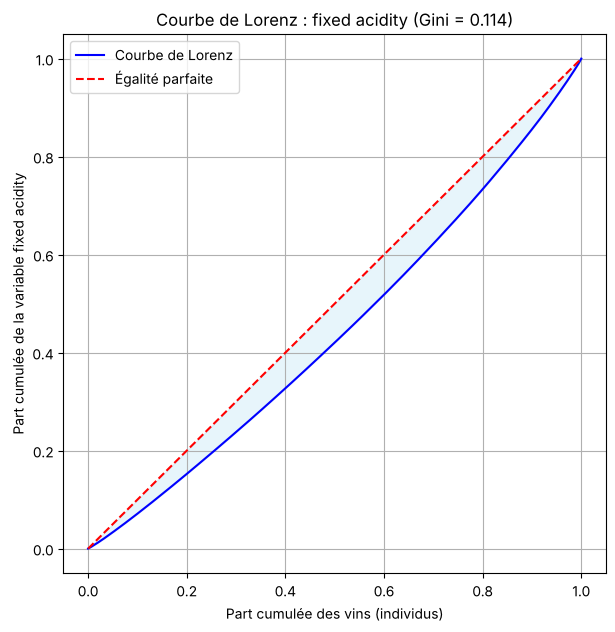

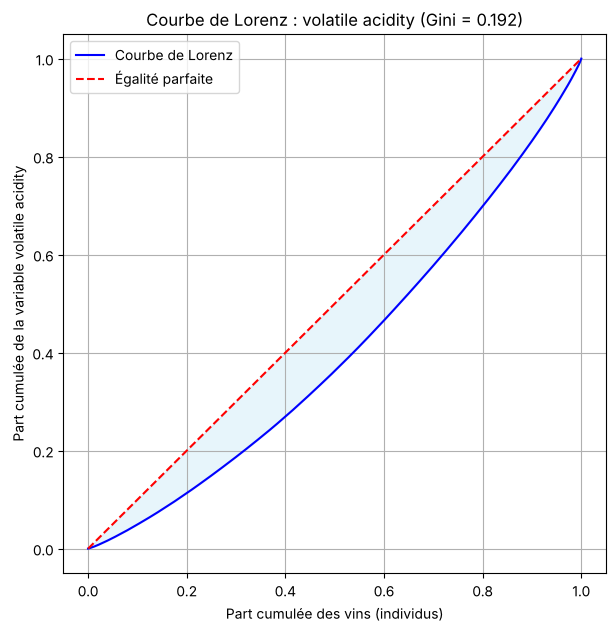

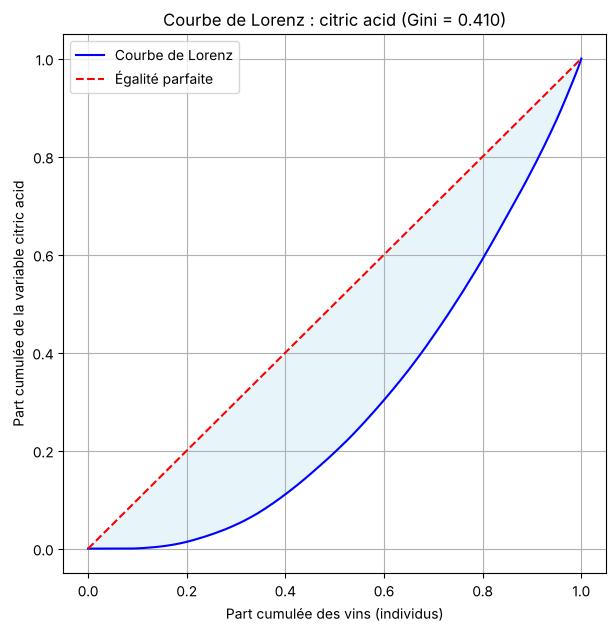

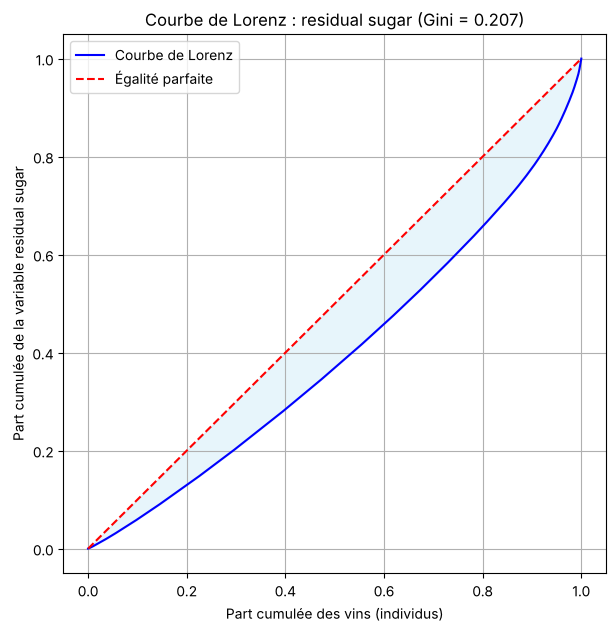

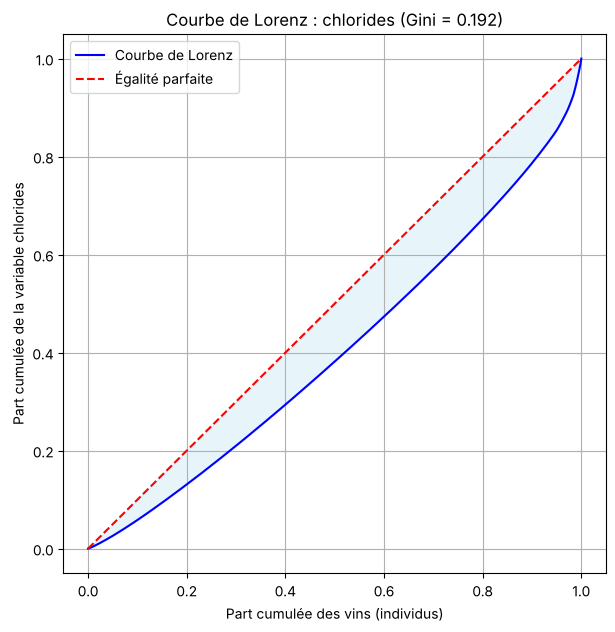

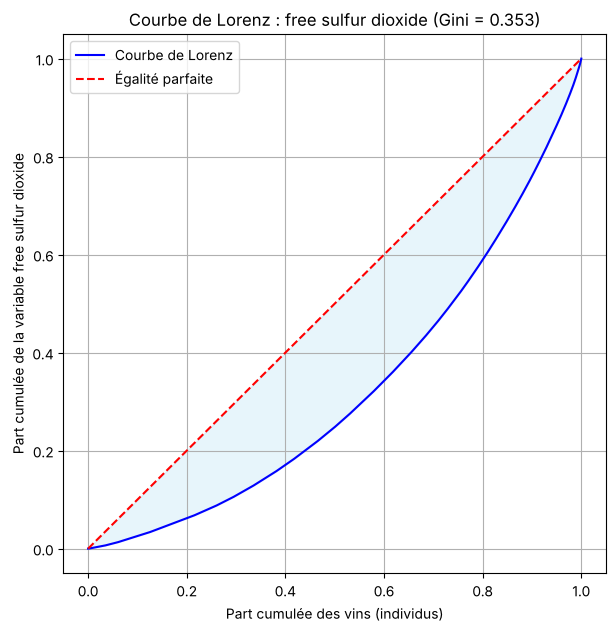

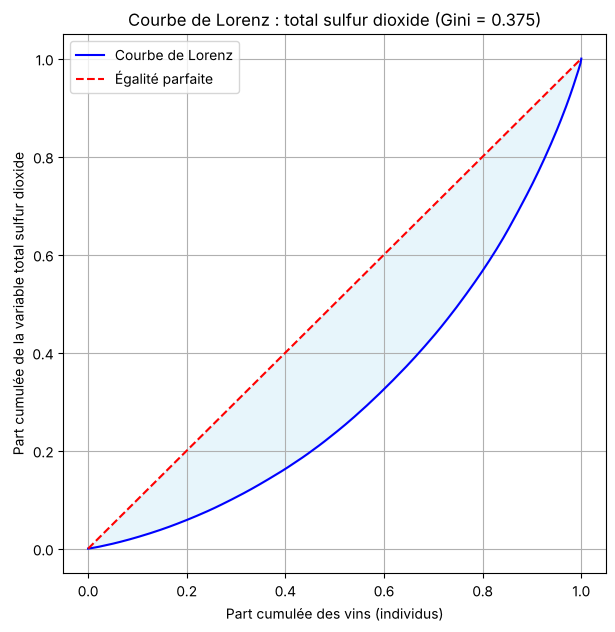

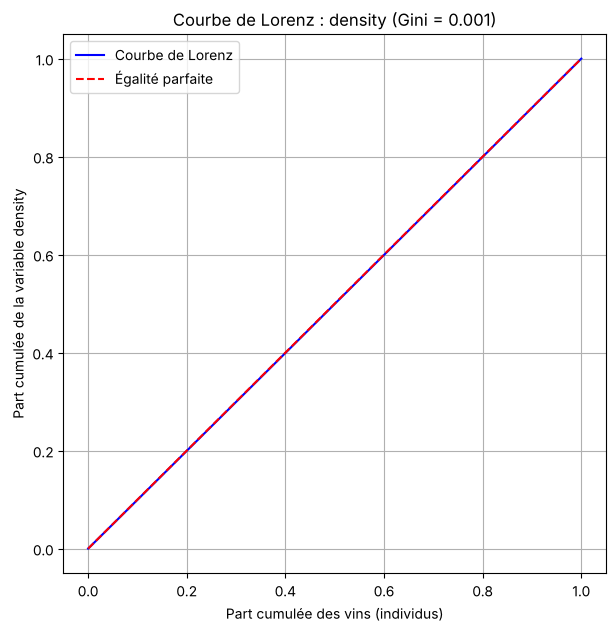

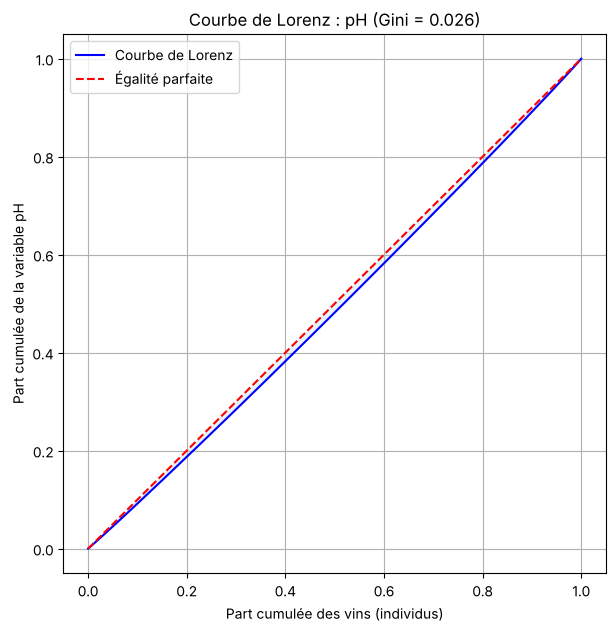

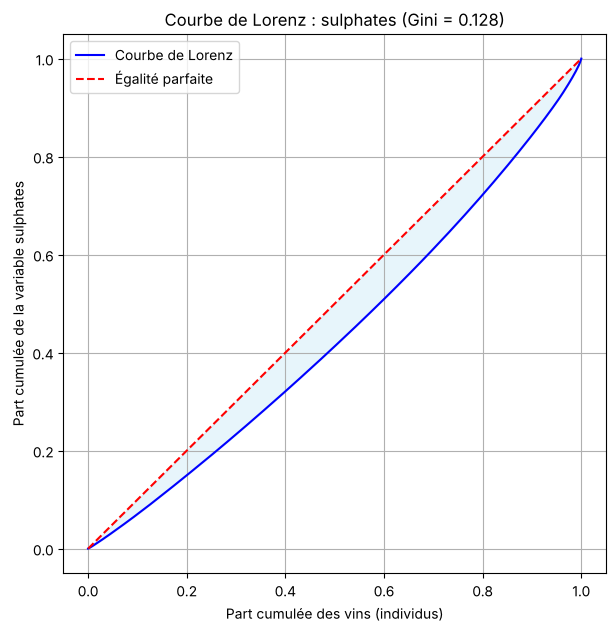

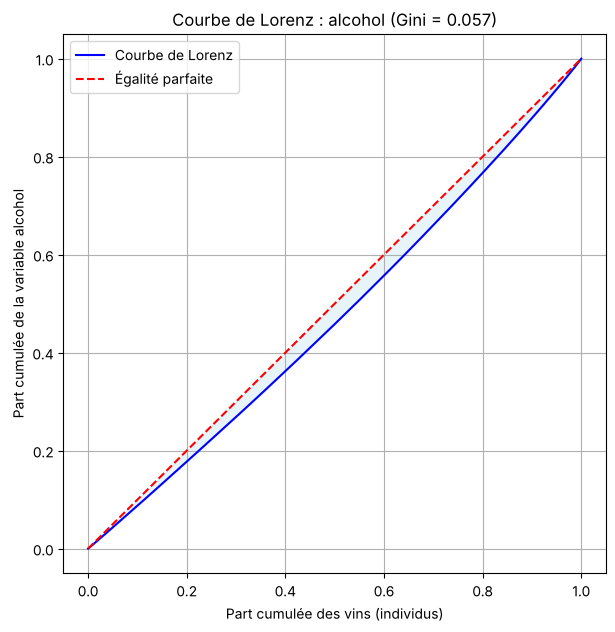

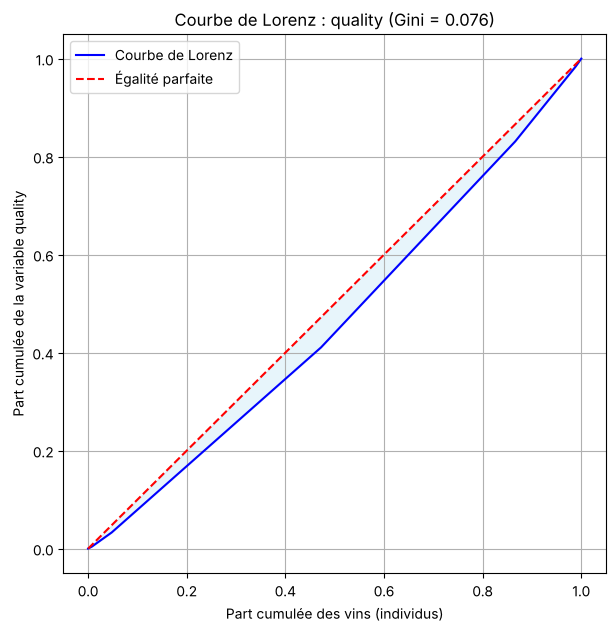


--- Classement des variables par indice de Gini ---
citric acid             0.410251
total sulfur dioxide    0.374910
free sulfur dioxide     0.353475
residual sugar          0.207184
volatile acidity        0.191730
chlorides               0.191533
sulphates               0.127883
fixed acidity           0.113902
quality                 0.076483
alcohol                 0.057262
pH                      0.026002
density                 0.001035
dtype: float64


In [9]:
# --- Boucle sur toutes les variables ---
resultats_gini = {}

print("Génération des courbes de Lorenz...")
for col in data.columns:
    gini_val = plot_lorenz_gini(data, col)
    resultats_gini[col] = gini_val

print("\n--- Classement des variables par indice de Gini ---")
# On trie du plus concentré au moins concentré
summary = pd.Series(resultats_gini).sort_values(ascending=False)
print(summary)

**À retenir :** les chlorures et le sucre résiduel sont très asymétriques (skewness > 4). L'acide citrique et le dioxyde de soufre sont les variables les plus concentrées (Gini ≈ 0,35 à 0,41), alors que la densité et le pH sont presque constants.